# TEST dashboard JWST

tous les tests / essais / avant  dashboard Final. le vrai code --> utils.py, Synthese.py et le dossier pages/

## chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PATH = "data/exoplanets.csv"
raw = pd.read_csv(PATH)

ParserError: Error tokenizing data. C error: Expected 1 fields in line 97, saw 92

j'a vais oublier que comme ça sa plante. 
le fichier commence par ~100 lignes de com NASA avec des # -> pandas comprend rien
--> fix : comment="#"

In [2]:
raw = pd.read_csv(PATH, comment="#", low_memory=False)
print(raw.shape)
print("nb planetes :", raw["pl_name"].nunique())

(38449, 92)
nb planetes : 5903


38k lignes pour 5900 planètes ?? -->  1 ligne = 1 publicatio pas 1 planète. si on compte les lignes on compte n'importe quoi
j'utilise default_flag == 1 = la mesure de référence. 

In [3]:
df = raw[raw["default_flag"] == 1].copy()
print("lignes :", len(df), "| planetes :", df["pl_name"].nunique())

lignes : 5903 | planetes : 5903


IMPORTANT  --> 1 ligne = 1 planete

## vérif du chiffre 55 dans l'AED (projet de base)

dans l'ancienne app il y avait "55 planètes en ZH (3,9 %)". je voulais le reprendre en KPI, du coup je vérifie avant

In [4]:
print(f"55 / {len(df)} = {55 / len(df):.1%}")

55 / 5903 = 0.9%


0,9 % et pas 3,9 %... le 55 était écrit en dur dans le html, aucun calcul derrière, on sait pas d'où il sort
--> on reprend rien de l'AED sans recalculer + toujours mettre le dénominateur

## zone habitable test 1 --> avec la température

première idée : habitable = pl_eqt ok pour de l'eau liquide. mais avant je regarde combien il manque de valeurs

In [5]:
cols = ["pl_rade", "pl_bmasse", "pl_eqt", "pl_insol", "pl_orbsmax", "st_teff", "st_rad", "sy_dist"]
for c in cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
(df[cols].isna().mean() * 100).round(1).sort_values(ascending=False)

pl_insol      86.5
pl_eqt        74.5
pl_bmasse     52.3
pl_orbsmax    37.9
pl_rade       25.2
st_rad        12.8
st_teff       11.5
sy_dist        2.2
dtype: float64

In [6]:
hz_temp = df["pl_eqt"].between(180, 310)
print("ZH par temp :", hz_temp.sum())
print("dont rayon < 2 :", (hz_temp & (df["pl_rade"] < 2)).sum())

ZH par temp : 58
dont rayon < 2 : 15


problèmes :
- pl_eqt vide à 74,5 % --> 3/4 du catalogue qui dégage direct
- pl_eqt c'est la température sans effet de serre (la Terre serait à ~255 K donc gelée). le seuil est au pif et sa bouge beaucoup selon les bornes

--> abandonné

## zone habitable test 2 --> avec l'orbite (HZD)

autre idée : on calcule les bords de la ZH avec la luminosité de l'étoile (Kopparapu) et on regarde si l'orbite tombe dedans
HZD : -1 = bord chaud, 0 = milieu, +1 = bord froid. plus besoin de pl_eqt

In [7]:
def compute_hzd(d):
    lum = d["st_rad"] ** 2 * (d["st_teff"] / 5778) ** 4   # luminosite en L soleil
    inner = np.sqrt(lum / 1.776)   # bord int (UA)
    outer = np.sqrt(lum / 0.32)    # bord ext (UA)
    return (d["pl_orbsmax"] - (inner + outer) / 2) / ((outer - inner) / 2)

df["HZD"] = compute_hzd(df)
print("calculable :", df["HZD"].notna().sum(), "/", len(df))
print("en ZH :", (df["HZD"].abs() <= 1).sum())

calculable : 2914 / 5903
en ZH : 162


In [8]:
# test avec la Terre, doit etre entre -1 et 1
terre = pd.DataFrame({"st_rad": [1.0], "st_teff": [5778], "pl_orbsmax": [1.0]})
compute_hzd(terre)

0   -0.509285
dtype: float64

la Terre --> -0,5 donc dedans, côté chaud. la formule marche
mais calculable que pour la moitié du catalogue (pl_orbsmax manque souvent)

## Remplir les Valeurs Manquantes

si pl_orbsmax manque sur la ligne de référence, une autre publication l'a peut-être. pareil pour l'étoile (même hostname)
--> médiane des autres lignes. avec fillna on touche pas aux valeurs qui existent déjà

In [9]:
filled = df.copy()
before = filled[["sy_dist", "st_rad", "st_teff", "pl_orbsmax", "pl_rade"]].isna().sum()

for col, key in [("sy_dist", "hostname"), ("st_rad", "hostname"), ("st_teff", "hostname"),
                 ("pl_orbsmax", "pl_name"), ("pl_rade", "pl_name")]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")
    med = raw.groupby(key)[col].median()
    filled[col] = filled[col].fillna(filled[key].map(med))

after = filled[["sy_dist", "st_rad", "st_teff", "pl_orbsmax", "pl_rade"]].isna().sum()
pd.DataFrame({"avant": before, "apres": after})

,avant,apres
sy_dist,128,123
st_rad,755,537
st_teff,676,393
pl_orbsmax,2239,292
pl_rade,1490,1452


In [10]:
filled["HZD"] = compute_hzd(filled)
print("calculable :", df["HZD"].notna().sum(), "->", filled["HZD"].notna().sum())
print("en ZH :", (df["HZD"].abs() <= 1).sum(), "->", (filled["HZD"].abs() <= 1).sum())

calculable : 2914 -> 5087
en ZH : 162 -> 249


gros gain. petit check avec des planètes connues

In [11]:
connues = ["TRAPPIST-1 e", "TRAPPIST-1 f", "Proxima Cen b", "TOI-700 d", "Kepler-452 b", "LHS 1140 b"]
filled.loc[filled["pl_name"].isin(connues), ["pl_name", "pl_rade", "sy_dist", "HZD"]].round(2)

,pl_name,pl_rade,sy_dist,HZD
27054,Kepler-452 b,1.63,551.73,-0.61
34676,LHS 1140 b,1.73,14.99,0.52
35367,Proxima Cen b,NaN,1.30,0.21
36642,TOI-700 d,1.07,31.13,-0.35
36769,TRAPPIST-1 e,0.92,NaN,-0.03
36775,TRAPPIST-1 f,1.04,NaN,0.74


- TRAPPIST-1 e et f : en ZH mais aucune distance, sur aucune ligne --> elles sautent des cibles
- Proxima b : pas de rayon (trouvée par vitesse radiale, elle transite pas)

j'ai pensé à mettre la distance de TRAPPIST à la main (~12 pc) mais non on modifie pas le dataset. on le signale dans le dashboard et c'est tout

petit check avant d'aller plus loin : est-ce que HZD c'est fiable ? je compare avec l'insolation (pl_insol) = la lumière que reçoit la planète. mêmes bornes que pour l'orbite

In [12]:
# l'insolation = la lumière reçue par rapport à la Terre (Terre = 1)
# mêmes bornes que la ZH par l'orbite : entre 0,32 et 1,776
df["pl_insol"] = pd.to_numeric(df["pl_insol"], errors="coerce")
print("pl_insol manquant :", f"{df['pl_insol'].isna().mean():.1%}")
hz_insol = df["pl_insol"].between(0.32, 1.776)
both = df["pl_insol"].notna() & filled["HZD"].notna()
same = (hz_insol == (filled["HZD"].abs() <= 1))[both]
print("ZH par insolation :", hz_insol.sum(), "planètes")
print("quand les 2 méthodes sont calculables (", both.sum(), "planètes ) elles sont d'accord à", f"{same.mean():.1%}")

pl_insol manquant : 86.5%
ZH par insolation : 54 planètes
quand les 2 méthodes sont calculables ( 784 planètes ) elles sont d'accord à 99.4%


pl_insol vide à 86,5 % donc inutilisable direct (pire que pl_eqt). mais quand les 2 sont calculables elles sont d'accord à 99,4 % --> HZD c'est bon, et avec beaucoup plus de planètes

## Choix Seuils Rayon et Distance

On ce demande :
--> rocheuse = rayon < combien ? proche = < combien de pc ? et sa change quoi

In [13]:
hz = filled["HZD"].abs() <= 1
rows = {}
for r in [1.5, 1.6, 2.0, 2.5]:
    rocky = hz & (filled["pl_rade"] < r)
    rows[f"rayon < {r}"] = {f"< {d} pc": int((rocky & (filled["sy_dist"] < d)).sum())
                            for d in [20, 30, 50, 100, 200]}
    rows[f"rayon < {r}"]["total"] = int(rocky.sum())
pd.DataFrame(rows).T

,< 20 pc,< 30 pc,< 50 pc,< 100 pc,< 200 pc,total
rayon < 1.5,1,1,5,7,7,14
rayon < 1.6,1,1,6,8,8,16
rayon < 2.0,2,2,9,12,12,29
rayon < 2.5,2,3,12,18,20,48


Sa bouge beaucoup (de 5 à 12 cibles à 50 pc). si je fige un chiffre dans le titre c'est un choix caché
--> sliders dans la sidebar et le titre se recalcule
par défaut 2 R⊕ (limite rocheuse / mini-Neptune) et 50 pc (ordre de grandeur pour JWST)
1,5 c'est trop strict, sa enlève LHS 1140 b (1,7) alors que c'est une cible connue

et le 2 × la Terre il sort d'où ? vraie coupure ou juste un chiffre rond ? je regarde la distribution des petites planètes

entre 1,5 et 2 : 728 | entre 2 et 2,5 : 730 | entre 1 et 1,5 : 709


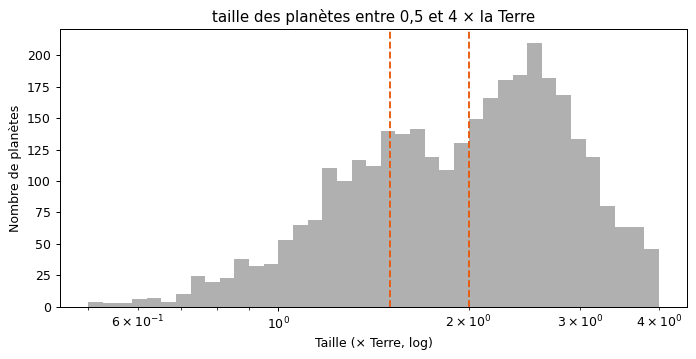

In [14]:
# distribution des petites planètes, bins en log
petites = filled.loc[filled["pl_rade"].between(0.5, 4), "pl_rade"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(petites, bins=np.logspace(np.log10(0.5), np.log10(4), 40), color="#B0B0B0")
ax.set_xscale("log")
for s in [1.5, 2.0]:
    ax.axvline(s, color="#E8590C", ls="--")
ax.set_xlabel("Taille (× Terre, log)"); ax.set_ylabel("Nombre de planètes")
ax.set_title("taille des planètes entre 0,5 et 4 × la Terre")
print("entre 1,5 et 2 :", petites.between(1.5, 2).sum(), "| entre 2 et 2,5 :", petites.between(2, 2.5).sum(),
      "| entre 1 et 1,5 :", petites.between(1, 1.5).sum())

2 bosses : une vers 1,3-1,4 et une vers 2,5, avec un creux vers 1,8 entre les deux
--> c'est la "vallée des rayons" : en dessous plutôt rocheux, au dessus plutôt gazeux. le 2 tombe juste après le creux, sa colle
pas dans le dashboard (trop technique pour le message) mais sa justifie le seuil

## Choix  KPI

je liste tout ce qu'on pourrait mettre et je trie

In [15]:
rocky_hz = hz & (filled["pl_rade"] < 2)
targets = rocky_hz & (filled["sy_dist"] < 50)
pd.Series({
    "nb exoplanetes": len(filled),
    "nb methodes": filled["discoverymethod"].nunique(),
    "1ere decouverte": int(filled["disc_year"].min()),
    "en ZH": int(hz.sum()),
    "rocheuses en ZH": int(rocky_hz.sum()),
    "cibles < 50 pc": int(targets.sum()),
    "% ZH sans rayon": f"{(hz & filled['pl_rade'].isna()).sum() / hz.sum():.0%}",
})

nb exoplanetes     5903
nb methodes          11
1ere decouverte    1992
en ZH               249
rocheuses en ZH      29
cibles < 50 pc        9
% ZH sans rayon     60%
dtype: object

pour le nb de méthodes j'ai quand même tenté un camembert, histoire de voir

discoverymethod
Transit                      4378
Radial Velocity              1121
Microlensing                  243
Imaging                        83
Transit Timing Variations      36
Eclipse Timing Variations      17
Name: count, dtype: int64


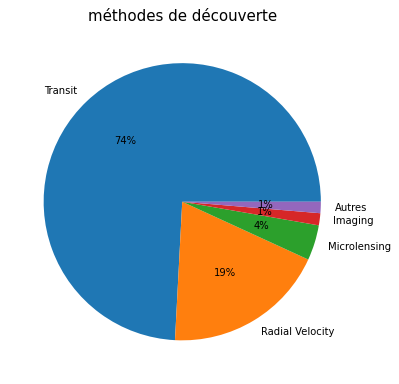

In [16]:
counts = filled["discoverymethod"].value_counts()
top = counts.head(4)
top["Autres"] = counts.iloc[4:].sum()
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(top, labels=top.index, autopct="%1.0f%%", textprops={"fontsize": 8})
ax.set_title("méthodes de découverte")
print(counts.head(6))

Transit = 74 %, le reste c'est des parts minuscules avec des étiquettes qui se marchent dessus (pas lisible du tout). et c'est une vanity de toute façon --> poubelle

et l'ESI de l'AED ? il faut la masse + la température

In [17]:
print("candidates :", rocky_hz.sum())
print("avec masse :", (rocky_hz & filled["pl_bmasse"].notna()).sum())
print("avec pl_eqt :", (rocky_hz & filled["pl_eqt"].notna()).sum())

candidates : 29
avec masse : 9
avec pl_eqt : 13


Masse dispo pour 9/29 seulement --> un ESI moyen ce serait la moyenne des mieux mesurées donc biaisé. abandonné

tri :
- nb exoplanètes, nb méthodes, 1ère découverte --> vanity, sa fait joli mais on décide rien avec
- en ZH --> sert juste de dénominateur
- **rocheuses en ZH** --> KPI 1, taille du vivier
- **cibles < 50 pc** --> KPI 2, c'est directement la liste pour JWST
- **% ZH sans rayon** --> KPI 3, dit où faire des observations de suivi
- ESI --> non

## Choix graphique Principal

nuage distance x rayon. (linéaire ou log ?)

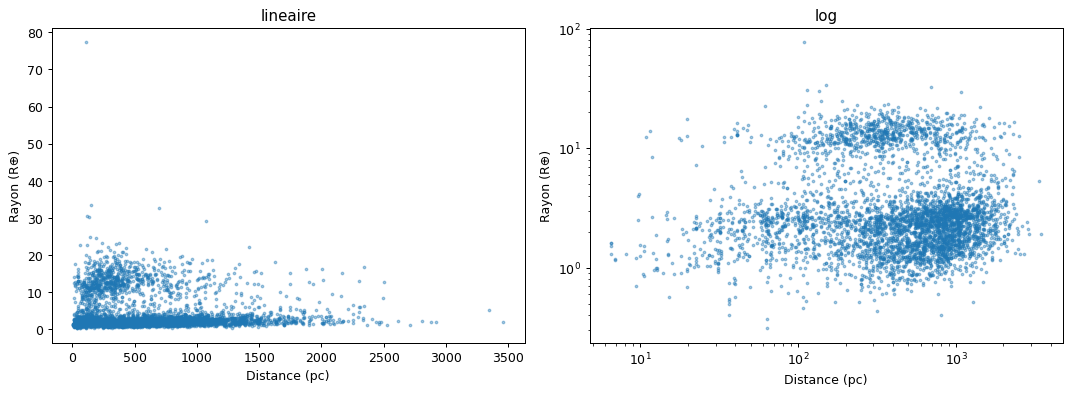

In [18]:
plot = filled.dropna(subset=["sy_dist", "pl_rade"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, log in zip(axes, [False, True]):
    ax.scatter(plot["sy_dist"], plot["pl_rade"], s=4, alpha=0.4)
    ax.set_xlabel("Distance (pc)"); ax.set_ylabel("Rayon (R⊕)")
    if log:
        ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title("log" if log else "lineaire")
plt.tight_layout()

linéaire = illisible les cibles sont dans 1 pixel en bas à gauche --> alors que en log c'ets bien beau (et on l'écrit sur les axes)

Et pour les couleur on test --> une couleur par méthode

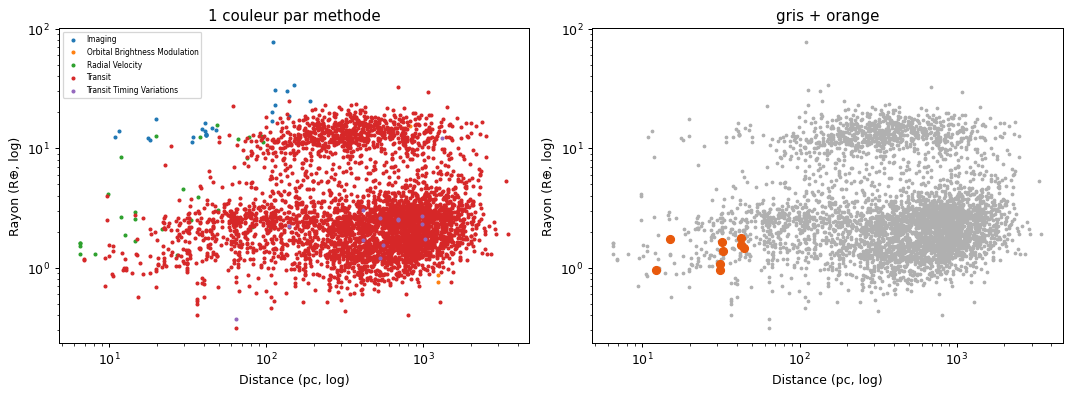

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m, g in plot.groupby("discoverymethod"):
    axes[0].scatter(g["sy_dist"], g["pl_rade"], s=5, label=m)
axes[0].set_title("1 couleur par methode")
axes[0].legend(fontsize=6)

is_target = targets.reindex(plot.index, fill_value=False)
axes[1].scatter(plot.loc[~is_target, "sy_dist"], plot.loc[~is_target, "pl_rade"], s=4, c="#B0B0B0")
axes[1].scatter(plot.loc[is_target, "sy_dist"], plot.loc[is_target, "pl_rade"], s=40, c="#E8590C")
axes[1].set_title("gris + orange")
for ax in axes:
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("Distance (pc, log)"); ax.set_ylabel("Rayon (R⊕, log)")
plt.tight_layout()

gauche : le rouge Transit prend tout on voit pas les cibles (pas top du tout). et la méthode sa sert à rien pour le message
droite : une seule couleur vive --> on voit les cibles direct (pré-attentif). le principe est respcter on capte en 5 secondes (même pas)
--> gris + orange + bleu discret pour les rocheuses en ZH trop loin (identifié mais pas l'info principale)

et une couleur continue selon la position dans la ZH, au lieu de 3 couleurs fixes ?

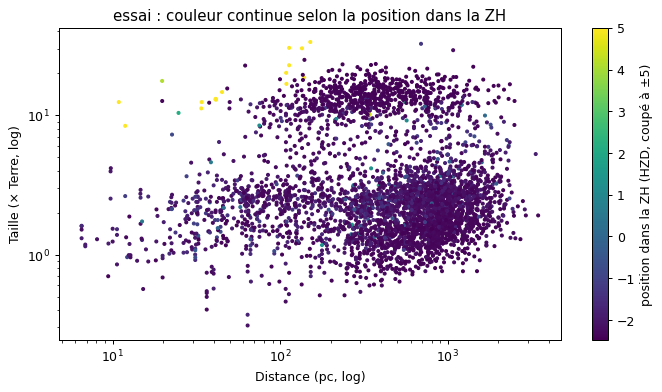

Text(0.5, 1.0, 'essai : couleur continue selon la position dans la ZH')

In [20]:
sub = plot.dropna(subset=["sy_dist", "pl_rade"]).copy()
sub["HZD"] = filled.loc[sub.index, "HZD"]
sub = sub.dropna(subset=["HZD"])
fig, ax = plt.subplots(figsize=(9, 4.5))
sc = ax.scatter(sub["sy_dist"], sub["pl_rade"], c=sub["HZD"].clip(-5, 5), cmap="viridis", s=5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Distance (pc, log)"); ax.set_ylabel("Taille (× Terre, log)")
fig.colorbar(sc, label="position dans la ZH (HZD, coupé à ±5)")
ax.set_title("essai : couleur continue selon la position dans la ZH")

presque tout est violet --> la grande majorité des planètes est beaucoup trop près de son étoile (HZD vers -2,5). on voit rien, l'oeil sait pas où regarder --> on reste sur 3 couleurs fixes

## Choix Graphiques des Autres Pages

pour le détail des cibles on a fait 1 onglet par graphique, sinon la page devient un mur de graphiques

- classement des cibles --> barres horizontales. les noms sont longs (TOI-6002 b...) donc à gauche c'est plus lisible. axe qui part de 0, sinon si l'axe commence à 30 pc une cible à 44 pc a l'air 14 fois plus loin qu'une à 31 alors que c'est même pas 1,5 fois
- découvertes par année --> barres empilées, orange = cible, bleu = trop loin. on voit d'un coup d'oeil quand elles ont été trouvées
- la liste complète --> juste un tableau, les cibles en premier. pas besoin d'un graphique pour une liste de 29 noms

page données manquantes --> barres avant / après côte à côte, axe de 0 à 100 % (c'est un pourcentage, on montre l'échelle entière)

avant de faire les barres, test de ce que sa donne si l'axe commence pas à 0

    pl_name  sy_dist
Gliese 12 b     12.2
 LHS 1140 b     15.0
  TOI-700 d     31.1
  TOI-700 e     31.1
 TOI-6002 b     32.0
 LP 890-9 c     32.4
  TOI-715 b     42.4
 TOI-2285 b     42.4
     K2-3 d     44.1


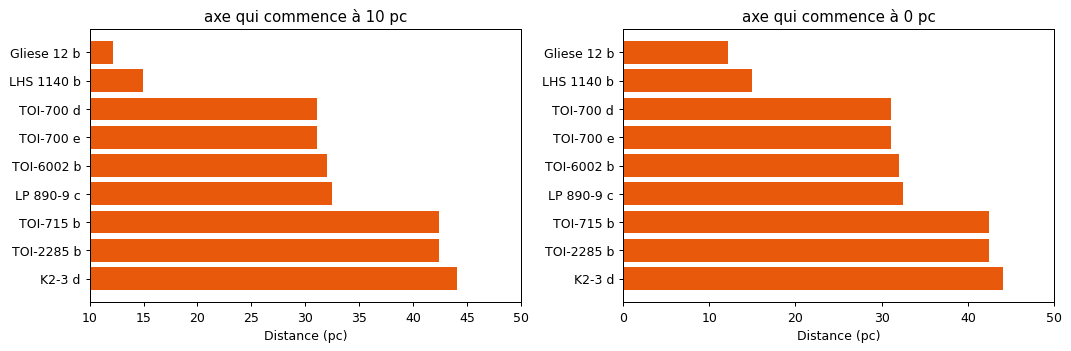

In [21]:
t = filled[targets].sort_values("sy_dist")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, start in zip(axes, [10, 0]):
    ax.barh(t["pl_name"], t["sy_dist"], color="#E8590C")
    ax.set_xlim(start, 50)
    ax.invert_yaxis()
    ax.set_xlabel("Distance (pc)")
    ax.set_title(f"axe qui commence à {start} pc")
plt.tight_layout()
print(t[["pl_name", "sy_dist"]].round(1).to_string(index=False))

axe à 10 --> Gliese 12 b a une barre minuscule et K2-3 d a l'air 15 fois plus loin. en vrai c'est 3,6 fois (12,2 pc contre 44,1)
--> axe à 0 obligatoire, sinon on ment avec le graphique

et plutôt qu'un classement par distance, un score qui mélange distance et taille ?

In [22]:
# score : plus proche = mieux, taille proche de la Terre = mieux. les poids c'est moi qui choisis
t = filled[targets].copy()
proche = 1 - t["sy_dist"] / 50
terre = 1 - (t["pl_rade"] - 1).abs()
for w in [0.5, 0.8]:
    t[f"score {w}"] = (w * proche + (1 - w) * terre).round(2)
    t[f"rang {w}"] = t[f"score {w}"].rank(ascending=False, method="min").astype(int)
t.sort_values("rang 0.5")[["pl_name", "sy_dist", "pl_rade", "score 0.5", "rang 0.5", "score 0.8", "rang 0.8"]]

,pl_name,sy_dist,pl_rade,score 0.5,rang 0.5,score 0.8,rang 0.8
906,Gliese 12 b,12.2100,0.958,0.86,1,0.80,1
36647,TOI-700 e,31.1265,0.953,0.67,2,0.49,3
36642,TOI-700 d,31.1265,1.073,0.65,3,0.49,3
34676,LHS 1140 b,14.9861,1.730,0.49,4,0.61,2
34723,LP 890-9 c,32.4298,1.367,0.49,4,0.41,5
36567,TOI-6002 b,32.0266,1.650,0.35,6,0.36,6
5076,K2-3 d,44.0727,1.458,0.33,7,0.20,8
36656,TOI-715 b,42.4048,1.550,0.30,8,0.21,7
36088,TOI-2285 b,42.4090,1.770,0.19,9,0.17,9


le classement change selon les poids que je choisis. LHS 1140 b passe de 4e à 2e juste en changeant 0,5 en 0,8
les poids c'est du pif donc le score aussi --> abandonné. classement simple par distance, que tout le monde comprend

## Kepler ou TESS ?

pour l'onglet des découvertes par année le premier titre c'était "presque toutes les candidates ont été découvertes ces dernières années". sauf qu'en regardant le graphique c'était l'inverse, la plupart datent de 2013-2016
du coup on vérifie qui les a trouvées

In [23]:
cand = filled[rocky_hz].copy()
cand["proche"] = cand["sy_dist"] < 50
cand.groupby(["proche", "disc_facility"]).size()

proche  disc_facility                               
False   K2                                               2
        Kepler                                          15
        La Silla Observatory                             1
        Multiple Observatories                           2
True    K2                                               1
        MEarth Project                                   1
        SPECULOOS Southern Observatory                   1
        Transiting Exoplanet Survey Satellite (TESS)     6
dtype: int64

les lointaines --> Kepler (15 sur 20). les proches --> TESS (6 sur 9)
Kepler regardait des étoiles loin de nous, TESS regarde les étoiles proches
--> titre corrigé : "les planètes trop lointaines datent de Kepler, les cibles sont récentes". et franchement c'est plus intéressant que l'ancien

du coup curieux, je regarde où sont les planètes dans le ciel (ra / dec)

planètes Kepler : 2781 | zone du ciel Kepler : ra [283.0, 298.0] dec [39.0, 50.0]


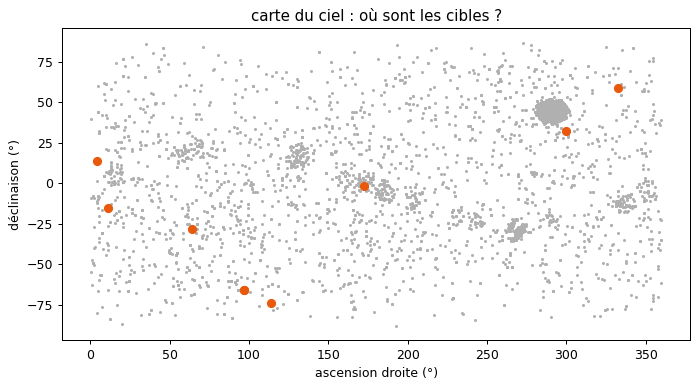

In [24]:
fig, ax = plt.subplots(figsize=(9, 4.5))
filled["ra"] = pd.to_numeric(filled["ra"], errors="coerce")
filled["dec"] = pd.to_numeric(filled["dec"], errors="coerce")
ax.scatter(filled["ra"], filled["dec"], s=2, c="#B0B0B0")
ax.scatter(filled.loc[targets, "ra"], filled.loc[targets, "dec"], s=40, c="#E8590C")
ax.set_xlabel("ascension droite (°)"); ax.set_ylabel("déclinaison (°)")
ax.set_title("carte du ciel : où sont les cibles ?")
kepler = filled["disc_facility"].eq("Kepler")
print("planètes Kepler :", kepler.sum(), "| zone du ciel Kepler : ra", filled.loc[kepler, "ra"].quantile([0.05, 0.95]).round(0).tolist(),
      "dec", filled.loc[kepler, "dec"].quantile([0.05, 0.95]).round(0).tolist())

le gros paquet en haut à droite (ra ~290°, dec ~45°) c'est le champ de Kepler --> il a fixé un seul coin du ciel, très loin. sa confirme
par contre les cibles sont éparpillées partout, la carte dit rien pour le message --> pas dans le dashboard

## Simplifier pour Comprehension

en relisant le dashboard y'a des truc trop technique pour les profanes. "rocheuse en zone habitable", "rayon", "parsecs"... quelqu'un qui connaît pas le sujet c'est compliqué.

changements :
- "rocheuse en zone habitable" --> **« type Terre »**, expliqué une seule fois en haut de la synthèse
- "rayon" --> "taille"
- un encadré de 2 lignes en haut : c'est quoi JWST + c'est quoi « type Terre »
- sous le graphique : "plus à gauche = plus proche, plus bas = plus petite"
- les titres disent la conclusion, pas le sujet. "Qui sont les 9 cibles ?" c'était une question, pas un message --> changé
- le menu affichait "app" --> fichiers renommés (Synthese.py, 1_Detail_des_cibles.py, 2_Donnees_manquantes.py) parce que streamlit prend le nom du fichier

et les parsecs sa parle à personne, on convertit les plus proches en années-lumière :

In [25]:
proches = filled[targets].sort_values("sy_dist")[["pl_name", "sy_dist"]].head(3)
proches["années-lumière"] = (proches["sy_dist"] * 3.26).round(0)
proches

,pl_name,sy_dist,années-lumière
906,Gliese 12 b,12.2100,40.0
34676,LHS 1140 b,14.9861,49.0
36642,TOI-700 d,31.1265,101.0


40 années-lumière pour la plus proche --> sa parle beaucoup plus que 12 pc
(moi tu me dit 12 pc je pense à un cybercafé.)

## bugs et corrections 

(y'en a toujours)

**bug 1 : la ligne de seuil part à 10^50** : add_vline(x=50) sur un axe log --> l'axe monte jusqu'à 10^80, aucun sens

In [26]:
import plotly.express as px

fig = px.scatter(plot.head(50), x="sy_dist", y="pl_rade", log_x=True)
fig.add_vline(x=50)
print("avant :", fig.layout.shapes[0].x0, "-> lu comme 10^50")

fig = px.scatter(plot.head(50), x="sy_dist", y="pl_rade", log_x=True)
fig.add_vline(x=np.log10(50))
print("apres :", round(fig.layout.shapes[0].x0, 3), "-> 10^1.699 = 50 pc")

avant : 50 -> lu comme 10^50
apres : 1.699 -> 10^1.699 = 50 pc


sur un axe log plotly veut le log10 de la valeur pour les formes. fix : np.log10(max_dist)

**bug 2 : lignes invisibles en thème sombre** : line_color="black" sur le thème sombre on voit rien --> gris #888

**choix : pas de flèche delta sur les KPIs** : st.metric(delta="sur 249") met une flèche verte ↑ comme si sa augmentait. c'est faux --> texte dans un st.caption à la place

**bug 3 : le chemin du csv casse en ligne** : "data/exoplanets.csv" marche que si on lance depuis le dossier. sur Streamlit Cloud ou depuis une autre page sa casse --> Path(__file__).parent / "data" / ...

**bug 4 : pyarrow plante sur la page détail** : `ImportError: pyarrow requires NumPy 2.0 or newer, found 1.26.4`. en créant le .venv, pip a pris la dernière version de pyarrow (la 26) qui veut numpy 2, alors que requirements.txt fixe numpy 1.26.4. sa plante que sur les pages avec un tableau (st.dataframe utilise pyarrow) --> pyarrow==15.0.0 ajouté dans requirements.txt. vu avant le déploiement heureusement, sur Streamlit Cloud sa aurait planté pareil

## ce qu'on garde au final

- default_flag == 1
- ZH = HZD (orbite), pas la température
- trous bouchés avec les autres publications
- TRAPPIST / Proxima : on le signale, on corrige pas à la main
- seuils en sliders, par défaut 2 R⊕ / 50 pc
- 3 KPIs : planètes « type Terre », assez proches pour JWST (< 50 pc), % taille inconnue
- graphique en log + gris/orange
- pas de flèche delta
- 1 onglet par graphique sur la page détail, axes des barres à 0
- vocabulaire simple : « type Terre », taille, années-lumière
- titres = la conclusion, pas le sujet
- pyarrow==15.0.0 dans requirements.txt